<a href="https://colab.research.google.com/github/alcasas/chatbotv2/blob/main/Retail_Bot_2_Avance_de_Actividad_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instalación de dependencias

In [2]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn icrawler tensorflow pillow

# Generación de intenciones

In [3]:
import os
import pandas as pd

# Crear estructura de carpetas del proyecto
for carpeta in ["datos", "imagenes/raw", "imagenes/train", "imagenes/val", "imagenes/test", "modelos", "resultados"]:
    os.makedirs(carpeta, exist_ok=True)

# Dataset balanceado (25 ejemplos por intención = 125 registros)
dataset_intenciones = [
    # saludo
    ("hola buenos dias", "saludo"), ("hola necesito ayuda con el sistema", "saludo"),
    ("buenas tardes retailbot", "saludo"), ("iniciar sesion de validacion", "saludo"),
    ("que tal como funciona este bot", "saludo"), ("hola estas activo", "saludo"),
    ("ayuda por favor soy nuevo en almacen", "saludo"), ("buenos dias equipo", "saludo"),
    ("saludos quiero empezar a trabajar", "saludo"), ("hola bot de inventario", "saludo"),
    ("inicio de turno hola", "saludo"), ("que puedes hacer por mi", "saludo"),
    ("necesito orientacion para capturar", "saludo"), ("hola me apoyas", "saludo"),
    ("buenas noches sistema", "saludo"), ("arrancar asistente", "saludo"),
    ("hola que tal", "saludo"), ("como uso la herramienta", "saludo"),
    ("menu principal ayuda", "saludo"), ("buen dia listo para validar", "saludo"),
    ("hola necesito asistencia", "saludo"), ("me puedes explicar tus funciones", "saludo"),
    ("estoy listo para empezar", "saludo"), ("hola retail bot", "saludo"),
    ("ayuda con los comandos", "saludo"),

    # consulta_categorias
    ("que marcas y equipos soportas", "consulta_categorias"), ("cuales son las categorias de hardware", "consulta_categorias"),
    ("lista de componentes validos", "consulta_categorias"), ("que tipo de piezas puedo registrar", "consulta_categorias"),
    ("validas tarjetas graficas y procesadores", "consulta_categorias"), ("dime el catalogo de hardware permitido", "consulta_categorias"),
    ("que equipos entran en el sistema", "consulta_categorias"), ("cuales categorias estan activas", "consulta_categorias"),
    ("soportas laptops y perifericos", "consulta_categorias"), ("que hardware reconoce el asistente", "consulta_categorias"),
    ("muestra las familias de productos", "consulta_categorias"), ("puedo validar monitores o solo cpu", "consulta_categorias"),
    ("que prefijos de categoria existen", "consulta_categorias"), ("dime que componentes tienes dados de alta", "consulta_categorias"),
    ("lista de hardware compatible", "consulta_categorias"), ("cuales son los grupos de inventario", "consulta_categorias"),
    ("que articulos de computo manejas", "consulta_categorias"), ("revisas memorias ram o solo gpu", "consulta_categorias"),
    ("ver categorias disponibles", "consulta_categorias"), ("que tipos de hardware puedo escanear", "consulta_categorias"),
    ("cuales son las lineas de producto", "consulta_categorias"), ("dime las categorias soportadas hoy", "consulta_categorias"),
    ("que piezas de computadora reconoces", "consulta_categorias"), ("catalogo de componentes disponibles", "consulta_categorias"),
    ("que hardware puedo consultar aqui", "consulta_categorias"),

    # validar_sku
    ("validar sku GPU-RTX4090-ASUS", "validar_sku"), ("revisar codigo CPU-I9-INTEL", "validar_sku"),
    ("verificar pieza LAP-M1MAX-APPLE", "validar_sku"), ("este codigo es correcto PER-MXMASTER-LOGI", "validar_sku"),
    ("checa si el formato del sku esta bien", "validar_sku"), ("valida la nomenclatura GPU-RX7900-AMD", "validar_sku"),
    ("el sku CPU-RYZEN7-AMD cumple la regla", "validar_sku"), ("comprobar etiqueta de producto", "validar_sku"),
    ("quiero verificar este codigo de barras", "validar_sku"), ("valudar sku LAP-XPS15-DELL", "validar_sku"),
    ("revisa si la clave del componente es valida", "validar_sku"), ("esta bien escrito este sku", "validar_sku"),
    ("necesito validar el codigo de esta tarjeta", "validar_sku"), ("verifica que la pieza coincida con el sku", "validar_sku"),
    ("comprueba el formato CAT-MODELO-MARCA", "validar_sku"), ("validar identificador de hardware", "validar_sku"),
    ("este codigo no parece valido revisalo", "validar_sku"), ("checar clave GPU-RTX3060-MSI", "validar_sku"),
    ("confirmar nomenclatura de esta caja", "validar_sku"), ("validar el codigo de este procesador", "validar_sku"),
    ("es correcto el sku de este periferico", "validar_sku"), ("revisar sintaxis de codigo", "validar_sku"),
    ("verifica si el sku corresponde al equipo", "validar_sku"), ("valida codigo de inventario", "validar_sku"),
    ("comprobar si la etiqueta tiene errores", "validar_sku"),

    # registro_inventario
    ("reporte diario 15 laptops y 20 perifericos", "registro_inventario"), ("registrar inventario de hoy 10 cpu", "registro_inventario"),
    ("cierre de caja 8 tarjetas de video vendidas", "registro_inventario"), ("ingresar al sistema 25 teclados", "registro_inventario"),
    ("reporte de ventas 5 gpu y 3 laptop", "registro_inventario"), ("capturar entrada de mercancia 40 cpu", "registro_inventario"),
    ("actualizar stock llegaron 12 monitores", "registro_inventario"), ("hacer el corte de inventario del dia", "registro_inventario"),
    ("anota 30 perifericos en almacen", "registro_inventario"), ("reporte 345 tarjetas de video", "registro_inventario"),
    ("registrar salida de 7 procesadores", "registro_inventario"), ("cierre de turno 14 equipos vendidos", "registro_inventario"),
    ("subir reporte operativo de hardware", "registro_inventario"), ("agregar 18 laptops al conteo", "registro_inventario"),
    ("contabilizar 50 piezas en bodega", "registro_inventario"), ("guardar movimiento de 9 gpu", "registro_inventario"),
    ("reporte de existencias actuales", "registro_inventario"), ("dar de alta 6 cpu nuevos", "registro_inventario"),
    ("registrar venta de 11 perifericos", "registro_inventario"), ("necesito capturar el inventario fisico", "registro_inventario"),
    ("corte diario 22 componentes", "registro_inventario"), ("ingresar lote de 16 tarjetas graficas", "registro_inventario"),
    ("reportar merma de 2 laptops", "registro_inventario"), ("conteo de piso 35 articulos", "registro_inventario"),
    ("registrar el reporte de hoy", "registro_inventario"),

    # identificar_componente - nueva intencion multimodal para apoyo visual en almacen
    ("que componente aparece en esta foto", "identificar_componente"), ("ayudame a identificar esta pieza de hardware", "identificar_componente"),
    ("no se que tipo de equipo es este", "identificar_componente"), ("clasifica la imagen de este producto", "identificar_componente"),
    ("a que categoria pertenece este articulo", "identificar_componente"), ("escanear componente para saber su tipo", "identificar_componente"),
    ("que pieza es la de la fotografia", "identificar_componente"), ("detecta que hardware tengo en la mano", "identificar_componente"),
    ("identificar equipo sin etiqueta", "identificar_componente"), ("esta caja no tiene sku que componente es", "identificar_componente"),
    ("reconocer hardware mediante camara", "identificar_componente"), ("dime si esto es una gpu o un cpu", "identificar_componente"),
    ("analiza la foto y dime que categoria es", "identificar_componente"), ("no reconozco esta pieza ayudame", "identificar_componente"),
    ("clasificar hardware visualmente", "identificar_componente"), ("que tipo de dispositivo es este", "identificar_componente"),
    ("identifica el producto de la imagen", "identificar_componente"), ("ver que componente estoy mostrando", "identificar_componente"),
    ("ayuda visual para clasificar pieza", "identificar_componente"), ("que categoria le asigno a esta foto", "identificar_componente"),
    ("revisar imagen de componente desconocido", "identificar_componente"), ("dime que articulo es este", "identificar_componente"),
    ("identificacion de hardware por imagen", "identificar_componente"), ("que pieza de computo es", "identificar_componente"),
    ("clasifica este componente por favor", "identificar_componente")
]

df = pd.DataFrame(dataset_intenciones, columns=["texto", "intencion"])
df.to_csv("datos/intenciones.csv", index=False, encoding="utf-8")
print("Dataset guardado exitosamente. Distribución de clases:")
print(df["intencion"].value_counts())


Dataset guardado exitosamente. Distribución de clases:
intencion
saludo                    25
consulta_categorias       25
validar_sku               25
registro_inventario       25
identificar_componente    25
Name: count, dtype: int64


# Procesamiento de lenguaje natural y categorizacion

--- EJEMPLO DE PREPROCESAMIENTO (ANTES -> DESPUÉS) ---
Original : Validar SKU GPU-RTX4090-ASUS
Procesado: valid sku gpurtx4090asus

Original : Este código NO parece válido, revísalo!
Procesado: codig no parec val revisal

Original : Reporte diario: 15 laptops y 20 periféricos
Procesado: report diari 15 laptops 20 perifer


================ LinearSVC (SVM) (Accuracy: 53.12%) ================
                        precision    recall  f1-score   support

   consulta_categorias       0.50      0.43      0.46         7
identificar_componente       0.27      0.50      0.35         6
   registro_inventario       0.67      0.33      0.44         6
                saludo       0.71      0.71      0.71         7
           validar_sku       0.80      0.67      0.73         6

              accuracy                           0.53        32
             macro avg       0.59      0.53      0.54        32
          weighted avg       0.59      0.53      0.54        32


================ Multinomi

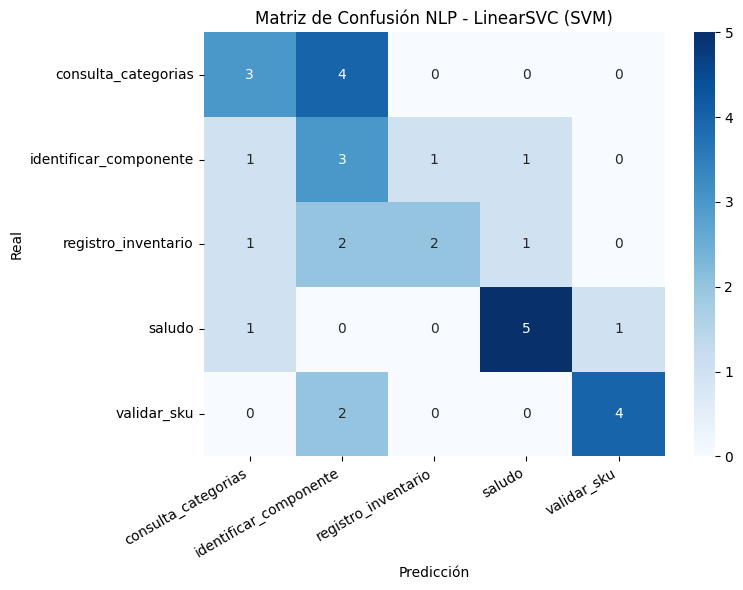

In [12]:
import re
import joblib
import nltk
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

nltk.download("stopwords", quiet=True)

# cargar datos
df = pd.read_csv("datos/intenciones.csv")
X_train, X_test, y_train, y_test = train_test_split(
    df["texto"], df["intencion"], test_size=0.25, random_state=42, stratify=df["intencion"]
)

# preprocesamiento de texto
stop_words_es = set(stopwords.words("spanish")) - {"no", "ni", "nunca", "sin"}
stemmer = SnowballStemmer("spanish")

def limpiar_y_normalizar(textos):
    resultados = []
    for s in textos:
        # normalizacion
        s_norm = re.sub(r"[^a-záéíóúñ0-9\s]", "", str(s).lower())
        # tokenizacion
        tokens = re.findall(r"\b\w+\b", s_norm)
        # eliminacion de stopwords + stemming
        tokens_proc = [stemmer.stem(t) for t in tokens if t not in stop_words_es]
        resultados.append(" ".join(tokens_proc))
    return resultados

# antes vs despues
ejemplos_demo = ["Validar SKU GPU-RTX4090-ASUS", "Este código NO parece válido, revísalo!", "Reporte diario: 15 laptops y 20 periféricos"]
print("--- EJEMPLO DE PREPROCESAMIENTO (ANTES -> DESPUÉS) ---")
for orig, proc in zip(ejemplos_demo, limpiar_y_normalizar(ejemplos_demo)):
    print(f"Original : {orig}\nProcesado: {proc}\n")

# comparativa de clasificadores
modelos_nlp = {
    "LinearSVC (SVM)": LinearSVC(class_weight="balanced", random_state=42),
    "Multinomial Naive Bayes": MultinomialNB()
}

mejor_modelo = None
mejor_acc = 0

for nombre, clf in modelos_nlp.items():
    pipe = Pipeline([
        ("preprocesamiento", FunctionTransformer(limpiar_y_normalizar, validate=False)),
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("clasificador", clf)
    ])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"\n================ {nombre} (Accuracy: {acc:.2%}) ================")
    print(classification_report(y_test, preds, zero_division=0))
    if acc >= mejor_acc:
        mejor_acc = acc
        mejor_modelo = pipe
        mejor_nombre = nombre

# eleccion de el mejor modelo y graficar matriz de confusion
joblib.dump(mejor_modelo, "modelos/clasificador_texto.joblib")
preds_final = mejor_modelo.predict(X_test)
etiquetas = sorted(df["intencion"].unique())
cm = confusion_matrix(y_test, preds_final, labels=etiquetas)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etiquetas, yticklabels=etiquetas)
plt.title(f"Matriz de Confusión NLP - {mejor_nombre}")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("resultados/matriz_confusion_nlp.png", dpi=300)
plt.show()


# Visualización y CNN

Clase 'cpu': 56 válidas -> Train: 39, Val: 8, Test: 9
Clase 'gpu': 53 válidas -> Train: 37, Val: 7, Test: 9
Clase 'laptop': 64 válidas -> Train: 44, Val: 9, Test: 11
Clase 'perifericos': 63 válidas -> Train: 44, Val: 9, Test: 10
Found 164 files belonging to 4 classes.
Found 33 files belonging to 4 classes.
Found 39 files belonging to 4 classes.
Clases visuales detectadas: ['cpu', 'gpu', 'laptop', 'perifericos']
Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.3659 - loss: 1.5599 - val_accuracy: 0.4545 - val_loss: 1.3344
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.6829 - loss: 0.8767 - val_accuracy: 0.6970 - val_loss: 1.0801
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.7012 - loss: 0.6278 - val_accuracy: 0.6667 - val_loss: 0.8788
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 43s 2s/step - accuracy: 0.8415 - loss: 0.4851 - val_accuracy: 0.6970 - val_loss: 0.8155
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.8841 - loss: 0.37

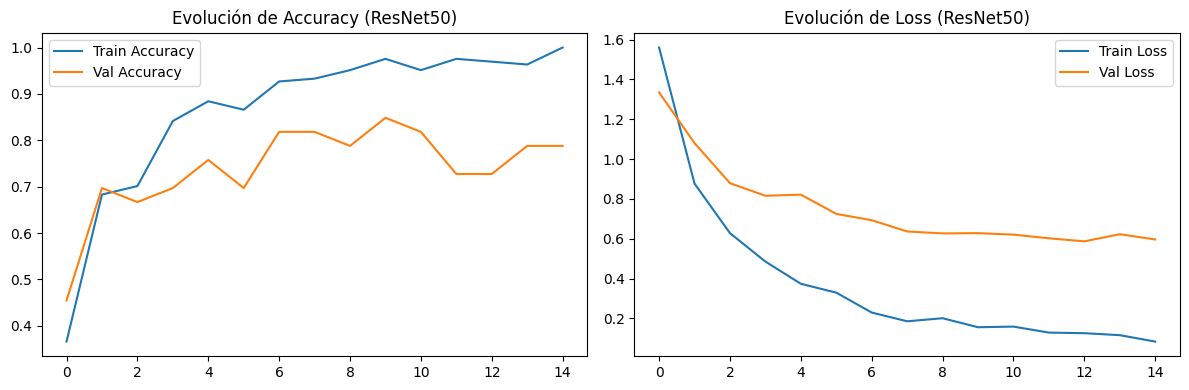

3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step

================ MÉTRICAS GLOBALES VISIÓN (TEST) ================
Accuracy : 0.8718
Precision: 0.8835
Recall   : 0.8718
F1-score : 0.8684

              precision    recall  f1-score   support

         cpu       0.80      0.89      0.84         9
         gpu       1.00      0.67      0.80         9
      laptop       0.83      0.91      0.87        11
 perifericos       0.91      1.00      0.95        10

    accuracy                           0.87        39
   macro avg       0.89      0.87      0.87        39
weighted avg       0.88      0.87      0.87        39



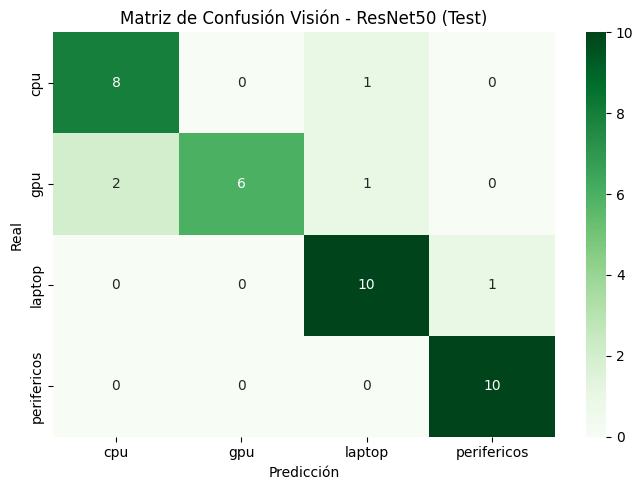

In [13]:
import os
import shutil
import random
import requests
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from icrawler.builtin import BingImageCrawler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# limpiar archivos anteriores
for split in ["train", "val", "test"]:
    shutil.rmtree(f"imagenes/{split}", ignore_errors=True)
    os.makedirs(f"imagenes/{split}", exist_ok=True)

# descarga de imagenes
consultas_bing = {
    "cpu": "intel processor cpu",
    "gpu": "nvidia graphics card gpu",
    "laptop": "laptop computer",
    "perifericos": "computer keyboard mouse"
}

consultas_wiki = {
    "cpu": "microprocessor CPU",
    "gpu": "graphics card GPU",
    "laptop": "laptop computer",
    "perifericos": "computer keyboard"
}

def descargar_wikimedia(query, carpeta_destino, limite=35):
    url = "https://commons.wikimedia.org/w/api.php"
    headers = {"User-Agent": "RetailBotEducationalProject/2.0"}
    params = {
        "action": "query",
        "generator": "search",
        "gsrsearch": f"filetype:bitmap {query}",
        "gsrnamespace": 6,
        "gsrlimit": limite,
        "prop": "imageinfo",
        "iiprop": "url",
        "iiurlwidth": 640,
        "format": "json"
    }
    try:
        r = requests.get(url, params=params, headers=headers, timeout=15).json()
        pages = r.get("query", {}).get("pages", {})
        for i, page in enumerate(pages.values()):
            img_url = page.get("imageinfo", [{}])[0].get("thumburl")
            if img_url:
                img_data = requests.get(img_url, headers=headers, timeout=10).content
                with open(os.path.join(carpeta_destino, f"wiki_{i:03d}.jpg"), "wb") as f:
                    f.write(img_data)
    except Exception:
        pass

for clase in consultas_bing.keys():
    dir_clase = f"imagenes/raw/{clase}"
    os.makedirs(dir_clase, exist_ok=True)
    if len(os.listdir(dir_clase)) < 35:
        crawler = BingImageCrawler(storage={"root_dir": dir_clase}, log_level=40)
        crawler.crawl(keyword=consultas_bing[clase], max_num=45)
        descargar_wikimedia(consultas_wiki[clase], dir_clase, limite=35)

# validacion de integridad de imagen y particionado
random.seed(42)
for clase in consultas_bing.keys():
    dir_origen = f"imagenes/raw/{clase}"
    archivos_validos = []
    for f in os.listdir(dir_origen):
        ruta = os.path.join(dir_origen, f)
        try:
            with Image.open(ruta) as img:
                img.verify()
            with Image.open(ruta) as img:
                img.convert("RGB")
            archivos_validos.append(ruta)
        except Exception:
            if os.path.exists(ruta):
                os.remove(ruta)

    random.shuffle(archivos_validos)
    n = len(archivos_validos)
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    particiones = {
        "train": archivos_validos[:n_train],
        "val": archivos_validos[n_train:n_train + n_val],
        "test": archivos_validos[n_train + n_val:]
    }

# separacion de categorias
    for split, lista_rutas in particiones.items():
        destino = f"imagenes/{split}/{clase}"
        os.makedirs(destino, exist_ok=True)
        for idx, r in enumerate(lista_rutas):
            with Image.open(r) as img:
                img.convert("RGB").save(os.path.join(destino, f"{clase}_{idx:03d}.jpg"), "JPEG")

    print(f"Clase '{clase}': {n} válidas -> Train: {len(particiones['train'])}, Val: {len(particiones['val'])}, Test: {len(particiones['test'])}")

# carga de datos a tensorflow
TAM = (224, 224)
BATCH = 16

train_ds = tf.keras.utils.image_dataset_from_directory("imagenes/train", image_size=TAM, batch_size=BATCH, seed=42)
val_ds = tf.keras.utils.image_dataset_from_directory("imagenes/val", image_size=TAM, batch_size=BATCH, seed=42)
test_ds = tf.keras.utils.image_dataset_from_directory("imagenes/test", image_size=TAM, batch_size=BATCH, shuffle=False)

clases_visuales = train_ds.class_names
print("Clases visuales detectadas:", clases_visuales)

# cnn con resnet50
base_model = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomZoom(0.1)(x)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(clases_visuales), activation="softmax")(x)

modelo_img = keras.Model(inputs, outputs)
modelo_img.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)

historia = modelo_img.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

# guardar modelo entrenado
modelo_img.save("modelos/clasificador_imagenes.keras")

# curvas de aprendizaje
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(historia.history["accuracy"], label="Train Accuracy")
plt.plot(historia.history["val_accuracy"], label="Val Accuracy")
plt.title("Evolución de Accuracy (ResNet50)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(historia.history["loss"], label="Train Loss")
plt.plot(historia.history["val_loss"], label="Val Loss")
plt.title("Evolución de Loss (ResNet50)")
plt.legend()
plt.tight_layout()
plt.savefig("resultados/curvas_entrenamiento_cnn.png", dpi=300)
plt.show()

# evaluaciones
y_real = np.concatenate([y.numpy() for _, y in test_ds])
probs = modelo_img.predict(test_ds)
y_pred = np.argmax(probs, axis=1)

acc_vis = accuracy_score(y_real, y_pred)
prec_vis = precision_score(y_real, y_pred, average="weighted", zero_division=0)
rec_vis = recall_score(y_real, y_pred, average="weighted", zero_division=0)
f1_vis = f1_score(y_real, y_pred, average="weighted", zero_division=0)

#resultados
print("\n================ MÉTRICAS GLOBALES VISIÓN (TEST) ================")
print(f"Accuracy : {acc_vis:.4f}")
print(f"Precision: {prec_vis:.4f}")
print(f"Recall   : {rec_vis:.4f}")
print(f"F1-score : {f1_vis:.4f}\n")
print(classification_report(y_real, y_pred, labels=list(range(len(clases_visuales))), target_names=clases_visuales, zero_division=0))

cm_vis = confusion_matrix(y_real, y_pred, labels=list(range(len(clases_visuales))))
plt.figure(figsize=(7, 5))
sns.heatmap(cm_vis, annot=True, fmt="d", cmap="Greens", xticklabels=clases_visuales, yticklabels=clases_visuales)
plt.title("Matriz de Confusión Visión - ResNet50 (Test)")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.tight_layout()
plt.savefig("resultados/matriz_confusion_vision.png", dpi=300)
plt.show()


# Multimodal

In [18]:
import glob

class RetailBotMultimodal:
    def __init__(self, ruta_modelo_texto, ruta_modelo_img, clases_vis, umbral_confianza=0.60):
        self.modelo_texto = joblib.load(ruta_modelo_texto)
        self.modelo_img = keras.models.load_model(ruta_modelo_img)
        self.clases_vis = clases_vis
        self.umbral = umbral_confianza
        self.patron_sku = r"([A-Z]{3,4}-[A-Z0-9]+-[A-Z]+)"
        self.mapa_prefijos = {
            "CPU": "cpu",
            "GPU": "gpu",
            "LAP": "laptop",
            "PER": "perifericos"
        }

    def clasificar_imagen(self, ruta_imagen):
        img = keras.utils.load_img(ruta_imagen, target_size=(224, 224))
        arr = keras.utils.img_to_array(img)
        lote = np.expand_dims(arr, axis=0)
        preds = self.modelo_img.predict(lote, verbose=0)[0]
        idx = int(np.argmax(preds))
        return self.clases_vis[idx], float(preds[idx])

    def procesar_interaccion(self, mensaje_usuario, ruta_imagen=None):
        # procesamiento y clasificacion de texto
        intencion = self.modelo_texto.predict([mensaje_usuario])[0]

        # procesamiento visual
        clase_visual, confianza = None, 0.0
        if ruta_imagen:
            clase_visual, confianza = self.clasificar_imagen(ruta_imagen)

        # multimodal
        respuesta = self._generar_respuesta(intencion, mensaje_usuario, clase_visual, confianza)

        return {
            "entrada_texto": mensaje_usuario,
            "entrada_imagen": ruta_imagen,
            "intencion_detectada": intencion,
            "clase_visual": clase_visual,
            "confianza_visual": round(confianza, 4),
            "respuesta_sistema": respuesta
        }

    def _generar_respuesta(self, intencion, texto, clase_vis, conf):
        # validacion de confianza visual
        if clase_vis is not None and conf < self.umbral:
            return (f"⚠️ Intención detectada: '{intencion}', pero la imagen no se identifica bien "
                    f"({conf:.1%}, posible clase '{clase_vis}'). Adjunta una imágen más clara para validar.")

        if intencion == "validar_sku":
            match = re.search(self.patron_sku, texto.upper())
            if not match:
                return "❌ ERROR: No se detectó un SKU con formato válido (CAT-MODELO-MARCA)."
            sku = match.group()
            prefijo = sku.split("-")[0]
            cat_esperada = self.mapa_prefijos.get(prefijo)

            if clase_vis:
                if cat_esperada == clase_vis:
                    return (f"✅ VALIDACIÓN MULTIMODAL EXITOSA: El SKU '{sku}' es válido y "
                            f"coincide con el componente detectado: '{clase_vis.upper()}' (confianza: {conf:.1%}).")
                else:
                    return (f"🚨 ALERTA DE DISCREPANCIA: El SKU '{sku}' indica categoría '{cat_esperada}', "
                            f"pero la imágen es de un componente tipo '{clase_vis.upper()}' (confianza: {conf:.1%}). Verifica la etiqueta.")
            return f"✅ Formato de SKU '{sku}' válido (adjunta foto del componente para verificación física)."

        elif intencion == "registro_inventario":
            numeros = re.findall(r"\b(\d+)\b", texto)
            cant = numeros[0] if numeros else "1"
            if clase_vis:
                return (f"✅ INVENTARIO REGISTRADO: Se añadieron {cant} unidad(es) de la categoría "
                        f"'{clase_vis.upper()}' identificada visualmente (confianza: {conf:.1%}).")
            return "⚠️ Indica la cantidad y adjunta una imagen del lote para automatizar el registro."

        elif intencion == "identificar_componente":
            if clase_vis:
                prefijo_sug = [k for k, v in self.mapa_prefijos.items() if v == clase_vis][0]
                return (f"🔍 COMPONENTE IDENTIFICADO: La pieza corresponde a '{clase_vis.upper()}' "
                        f"(confianza: {conf:.1%}). Prefijo SKU sugerido para etiquetado: '{prefijo_sug}-MODELO-MARCA'.")
            return "Por favor adjunta una fotografía del componente para identificar su categoría."

        elif intencion == "consulta_categorias":
            return "📋 Categorías soportadas (texto y visión): CPU (Procesadores), GPU (Tarjetas de Video), LAP (Laptops) y PER (Periféricos)."

        else:
            return "🤖 ¡Hola! Soy RetailBot v2.0 (Multimodal). Envíame un mensaje y una foto del componente para validar SKU, identificar piezas o registrar inventario."

# pruebas de flujo completo
bot_v2 = RetailBotMultimodal("modelos/clasificador_texto.joblib", "modelos/clasificador_imagenes.keras", clases_visuales)

# imagenes de pruebas
img_gpu_test = glob.glob("imagenes/test/gpu/*")[0]
img_cpu_test = glob.glob("imagenes/test/cpu/*")[0]

# imagen con ruido aleatorio
ruido = np.random.randint(0, 255, (224, 224, 3), dtype=np.uint8)
Image.fromarray(ruido).save("resultados/ruido.jpg")

casos_prueba = [
    ("Caso 1: Coincidencia correcta (Texto + Imagen GPU)", "Por favor valida el sku GPU-RTX4090-ASUS de esta tarjeta", img_gpu_test),
    ("Caso 2: Discrepancia SKU vs Imagen (Etiqueta mal pegada)", "Verificar pieza GPU-RTX3080-MSI", img_cpu_test),
    ("Caso 3: Identificación visual para inventario", "Que componente es este y registra 12 unidades", img_cpu_test),
    ("Caso 4: Imagen fuera de dominio / Baja confianza", "Identifica este componente de hardware", "resultados/ruido.jpg")
]

for titulo, msg, img_path in casos_prueba:
    print(f"\n--- {titulo} ---")
    res = bot_v2.procesar_interaccion(msg, img_path)
    for k, v in res.items():
        print(f"  {k}: {v}")


--- Caso 1: Coincidencia correcta (Texto + Imagen GPU) ---
  entrada_texto: Por favor valida el sku GPU-RTX4090-ASUS de esta tarjeta
  entrada_imagen: imagenes/test/gpu/gpu_004.jpg
  intencion_detectada: validar_sku
  clase_visual: cpu
  confianza_visual: 0.9915
  respuesta_sistema: 🚨 ALERTA DE DISCREPANCIA: El SKU 'GPU-RTX4090-ASUS' indica categoría 'gpu', pero la imágen es de un componente tipo 'CPU' (confianza: 99.2%). Verifica la etiqueta.

--- Caso 2: Discrepancia SKU vs Imagen (Etiqueta mal pegada) ---
  entrada_texto: Verificar pieza GPU-RTX3080-MSI
  entrada_imagen: imagenes/test/cpu/cpu_006.jpg
  intencion_detectada: identificar_componente
  clase_visual: laptop
  confianza_visual: 0.9887
  respuesta_sistema: 🔍 COMPONENTE IDENTIFICADO: La pieza corresponde a 'LAPTOP' (confianza: 98.9%). Prefijo SKU sugerido para etiquetado: 'LAP-MODELO-MARCA'.

--- Caso 3: Identificación visual para inventario ---
  entrada_texto: Que componente es este y registra 12 unidades
  entrada_imagen

# Interacción (zona de funcionamiento/pruebas)

In [17]:
!pip install -q gradio

import gradio as gr
import os
import joblib
from tensorflow import keras

# asegurar bot en variables globales
if "bot_v2" not in globals():
    clases_vis = sorted(os.listdir("imagenes/train"))
    bot_v2 = RetailBotMultimodal(
        "modelos/clasificador_texto.joblib",
        "modelos/clasificador_imagenes.keras",
        clases_vis
    )

def responder_chat(mensaje, historial):
    # gradio entrega un diccionario: {"text": str, "files": list}
    texto = mensaje.get("text", "").strip() if isinstance(mensaje, dict) else str(mensaje).strip()
    archivos = mensaje.get("files", []) if isinstance(mensaje, dict) else []

    ruta_imagen = archivos[0] if archivos else None

    if not texto and not ruta_imagen:
        return "⚠️ Por favor escribe una instrucción o adjunta la fotografía de un componente de hardware."

    # si el usuario sube solo una imagen la intencion es identificacion
    if not texto and ruta_imagen:
        texto = "Identifica este componente de hardware"

    resultado = bot_v2.procesar_interaccion(texto, ruta_imagen)

    detalle_tecnico = f"🧠 **Intención NLP:** `{resultado['intencion_detectada']}`"
    if resultado["clase_visual"]:
        detalle_tecnico += (
            f" | 👁️ **Visión CNN:** `{resultado['clase_visual'].upper()}` "
            f"({resultado['confianza_visual']*100:.1f}% confianza)"
        )

    return f"{detalle_tecnico}\n\n{resultado['respuesta_sistema']}"

# instancia de gradio
demo = gr.ChatInterface(
    fn=responder_chat,
    multimodal=True,
    title="🤖 RetailBot v2.0 — Asistente Multimodal de Validación de Hardware",
    description=(
        "Escribe un comando (ej. *'valida sku GPU-RTX4090-ASUS'*, *'registra 15 unidades'*, "
        "*'qué componente es este'*) y opcionalmente adjunta la foto de un CPU, GPU, Laptop o Periférico."
    ),
    textbox=gr.MultimodalTextbox(
        file_types=["image"],
        placeholder="Escribe tu mensaje aquí o adjunta una imagen con el ícono + ...",
        show_label=False
    )
)

demo.launch(inline=True, share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c964c63be84020c456.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
